In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [3]:
# 1. Load Dataset
df = pd.read_csv('Mobile phone price.csv')

# Clean column headers
df.columns = df.columns.str.strip()

In [4]:
# 2. Data Cleaning & Feature Extraction (Using Raw Strings 'r' for Regex)
# Extract numeric values from Storage and RAM
df['Storage'] = df['Storage'].astype(str).str.extract(r'(\d+)').astype(float)
df['RAM'] = df['RAM'].astype(str).str.extract(r'(\d+)').astype(float)

# Extract numeric value from Screen Size
df['Screen Size (inches)'] = df['Screen Size (inches)'].astype(str).str.extract(r'([\d.]+)').astype(float)

# Extract price numbers (removes $, commas, extra spaces)
df['Price ($)'] = df['Price ($)'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

# Extract primary camera MP (first number from setup like '12 + 12 + 12')
def get_primary_camera(val):
    nums = re.findall(r'[\d.]+', str(val))
    return float(nums[0]) if nums else np.nan

df['Primary_Camera_MP'] = df['Camera (MP)'].apply(get_primary_camera)

# Drop missing rows if any conversion fails
df_clean = df.dropna(subset=['Storage', 'RAM', 'Screen Size (inches)', 'Primary_Camera_MP', 'Battery Capacity (mAh)', 'Price ($)'])


In [5]:
# 3. Define Features (X) & Target (y)
X = df_clean[['Brand', 'Storage', 'RAM', 'Screen Size (inches)', 'Primary_Camera_MP', 'Battery Capacity (mAh)']]
y = df_clean['Price ($)']

In [6]:
# 4. Setup Pipeline (One-Hot Encoding for Brand + Linear Regression)
categorical_cols = ['Brand']
numerical_cols = ['Storage', 'RAM', 'Screen Size (inches)', 'Primary_Camera_MP', 'Battery Capacity (mAh)']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

In [7]:
# 5. Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Storage', 'RAM',
                                                   'Screen Size (inches)',
                                                   'Primary_Camera_MP',
                                                   'Battery Capacity (mAh)']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Brand'])])),
                ('regressor', LinearRegression())])

In [8]:
# 6. Evaluate Model
y_pred = model.predict(X_test)

print(f"R-squared (R2 Score): {r2_score(y_test, y_pred):.4f}")
print(f"Mean Absolute Error (MAE): ${mean_absolute_error(y_test, y_pred):.2f}")
print(f"Root Mean Squared Error (RMSE): ${np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")


R-squared (R2 Score): 0.7895
Mean Absolute Error (MAE): $89.88
Root Mean Squared Error (RMSE): $138.69


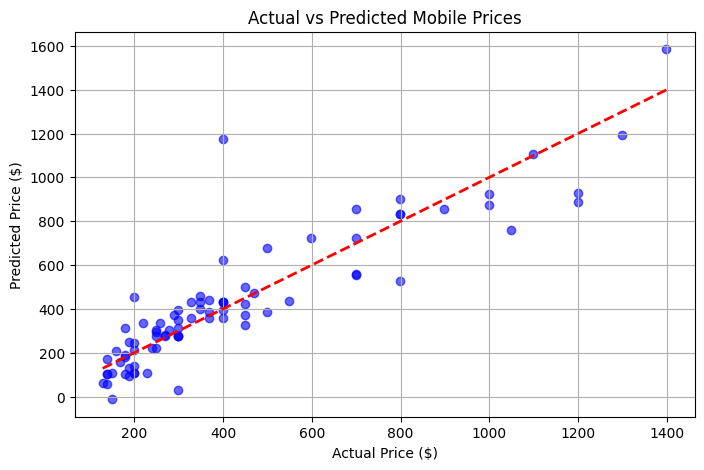

In [9]:
# 7. Visualization
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted Mobile Prices")
plt.grid(True)
plt.show()



In [10]:
# 8. Test Custom Sample Prediction
sample = pd.DataFrame([{
    'Brand': 'Samsung',
    'Storage': 128.0,
    'RAM': 8.0,
    'Screen Size (inches)': 6.5,
    'Primary_Camera_MP': 48.0,
    'Battery Capacity (mAh)': 5000
}])

pred_price = model.predict(sample)
print(f"\nEstimated Price for Sample Phone: ${pred_price[0]:.2f}")


Estimated Price for Sample Phone: $572.24
